# 02 · Experiments and results: INN and ATC for drug sales forecasting and cold start

This notebook presents the experiment protocol and the results produced by `scripts/run_experiments.py`
(training) and `scripts/analyze_results.py` (tables and figures). Training all models takes about 1.5 hours on 8 free CPU cores,
so by default the notebook reads the saved results; set `RUN_EXPERIMENTS = True` to retrain from scratch.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

import pandas as pd
from IPython.display import Image, Markdown, display

from teva_forecast import analysis as AN, config, experiments as E, plotting as P

pd.set_option("display.max_colwidth", 80)
P.apply_style()
import json, subprocess

RUN_EXPERIMENTS = False
if RUN_EXPERIMENTS:
    subprocess.run([sys.executable, str(ROOT / "scripts" / "run_experiments.py")], check=True)
    subprocess.run([sys.executable, str(ROOT / "scripts" / "analyze_results.py")], check=True)

T = lambda name: pd.read_csv(config.TABLES_DIR / f"{name}.csv")
F = lambda name: display(Image(filename=str(config.FIGURES_DIR / f"{name}.png")))

## 1. Protocol

* **Forecasting task:** monthly packs per SKU, 12 months ahead. A forecast is issued at the end of December for each month of the next year
  (horizon = calendar month), so every feature is computed from data up to the December origin.
* **Temporal split:** training targets 2020–2021 → **validation 2022** (loss function, number of trees, choice of the best baseline);
  training targets 2020–2022 → **test 2023** (reported once). No random shuffling of time.
* **Scenarios:** A existing drug; B new SKU whose INN is sold by the donors of both cross-fitted models; C new INN with known ATC;
  D unseen ATC level-2 group; D1 unseen ATC level-1 group; N real launches of 2023 (launch-date split). B, C, D and D1 are *simulated*
  cold starts on products that have history; held-out products are removed from training, from all peer statistics and from feature construction.
* **Ablation:** each scenario trains four CatBoost arms with identical control features: no INN/ATC, INN only, ATC only, INN + ATC
  (plus INN + ATC + category codes in A and B).
* **INN and ATC enter as peer statistics, by cross-fitting:** group statistics (INN, INN × form, ATC levels, form, global) are computed
  from donor SKUs that are disjoint from the SKUs a model is trained on (two halves of the pool, roles swapped, forecasts averaged), so a
  training SKU's own sales never shape its features. Raw INN/ATC codes are tested only in a sensitivity arm (A and B).
* **Loss:** chosen on validation 2022 among RMSE, Tweedie (p = 1.5) and MAE as the lowest mean WAPE over A and B, among losses whose
  forecast keeps the total volume within ±50%; this excludes near-constant median forecasts that WAPE alone would reward.
* **Metrics:** MAE, RMSE and WAPE on SKU-months, plus total-volume bias, WAPE of 12-month SKU totals and the Spearman correlation
  of SKU totals. A zero forecast (WAPE = 1 by definition) is shown as a reference for the cold-start scenarios.

In [2]:
for k, v in E.SCENARIOS.items():
    print(f"{k:>2}: {v}")
print(json.dumps(json.loads((config.MODELS_DIR / "training_parameters.json").read_text())["catboost"], indent=1))

 A: Existing drug: own sales history available
 B: New product, known INN: SKU (and identical twins) held out
 C: New INN, known ATC: all SKUs of the INN held out
 D: Unseen ATC group: ATC level-2 group and its INNs held out (only ATC1 known)
D1: Unseen ATC group, strict: ATC level-1 group and its INNs held out
 N: Real new launches: SKUs first sold in the evaluation year
{
 "iterations": 3000,
 "learning_rate": 0.05,
 "depth": 6,
 "l2_leaf_reg": 3.0,
 "max_ctr_complexity": 1,
 "random_seed": 42,
 "thread_count": -1,
 "allow_writing_files": false
}


## 2. Loss function selection (validation 2022 only)

In [3]:
T("loss_selection")

,scenario,fold,loss,iterations,n,MAE,RMSE,WAPE,bias,eligible
0,A,0,RMSE,36,124464,4255.830078,15008.220804,0.630522,0.218768,True
1,A,0,Tweedie:variance_power=1.5,578,124464,3029.723925,14528.438248,0.448869,0.150928,True
2,A,0,MAE,362,124464,3140.628646,21730.595595,0.465300,0.092234,True
3,B,0,RMSE,2/14,19380,8755.305848,15323.300611,1.569958,0.542137,False
4,B,0,Tweedie:variance_power=1.5,581/357,19380,7035.965652,15171.041249,1.261654,0.199702,True
5,B,0,MAE,50/60,19380,5259.835084,15595.884603,0.943167,-0.672840,False


## 3. Run log: training rows, evaluated SKUs and number of trees

In [4]:
runs = T("runs")
runs.groupby(["scenario", "split"]).agg(models=("arm", "size"), train_rows=("train_rows", "median"),
    donor_skus=("donor_skus", "median"), iterations=("iterations", "median"), minutes=("fit_seconds", lambda x: x.sum() / 60)).round(1)

models  train_rows  donor_skus  iterations  minutes
scenario split                                                          
A        test             5    380520.0     13762.0       578.0      3.2
         validation       5    256056.0     13762.0       578.0      3.3
B        test            50    151818.0      5505.0       431.5      9.1
         validation      20    102186.0      5504.5       361.5      3.6
C        test            40    152454.0      5505.0       119.0      2.1
         validation      16    102210.0      5504.5       119.0      1.3
D        test            40    143220.0      4751.5        31.5      0.6
         validation      16     97050.0      4697.0        26.5      0.9
D1       test            40    145764.0      4925.5        60.0      1.8
         validation      16     99750.0      4756.0       172.0      1.7
N        test             8    197038.5      6881.0       623.5      2.5
         validation       8    132759.0      6881.0       623.5      2.3

## 4. Main results, test 2023

All models of a scenario are evaluated on the same SKU-months. For B, C, D and D1 the five folds are pooled, so every product is evaluated once.

In [5]:
for metric in ("wape", "mae", "rmse", "bias", "wape_annual", "spearman_annual"):
    display(Markdown(f"**{metric.upper()}**"))
    display(T(f"results_test_{metric}").set_index("model").round(3))

**WAPE**

,A,B,C,D,D1,N
model,,,,,,
Zero forecast (reference),NaN,1.000,1.000,1.000,1.000,1.000
Naive (last month),0.298,NaN,NaN,NaN,NaN,NaN
Seasonal naive,0.397,NaN,NaN,NaN,NaN,NaN
Moving average (12),0.324,NaN,NaN,NaN,NaN,NaN
Global mean,NaN,1.325,1.387,1.383,1.380,2.620
Form mean,NaN,1.303,1.351,1.346,1.337,2.501
Hierarchical group mean,NaN,1.313,1.277,1.340,1.336,2.999
Hierarchical group median,NaN,1.001,0.994,0.967,0.967,1.474
Launch-age mean,NaN,NaN,NaN,NaN,NaN,1.169


**MAE**

,A,B,C,D,D1,N
model,,,,,,
Zero forecast (reference),NaN,7372.905,6719.772,6719.772,6719.772,2645.516
Naive (last month),1999.755,NaN,NaN,NaN,NaN,NaN
Seasonal naive,2667.318,NaN,NaN,NaN,NaN,NaN
Moving average (12),2177.034,NaN,NaN,NaN,NaN,NaN
Global mean,NaN,9767.527,9318.989,9293.914,9276.336,6930.209
Form mean,NaN,9609.335,9080.862,9041.663,8981.162,6617.392
Hierarchical group mean,NaN,9683.658,8578.773,9006.103,8978.825,7932.704
Hierarchical group median,NaN,7378.522,6678.671,6497.079,6500.467,3899.366
Launch-age mean,NaN,NaN,NaN,NaN,NaN,3091.430


**RMSE**

...

,A,B,C,D,D1,N
model,,,,,,
Zero forecast (reference),NaN,-1.000,-1.000,-1.000,-1.000,-1.000
Naive (last month),0.066,NaN,NaN,NaN,NaN,NaN
Seasonal naive,0.013,NaN,NaN,NaN,NaN,NaN
Moving average (12),0.013,NaN,NaN,NaN,NaN,NaN
Global mean,NaN,0.016,0.114,0.105,0.105,1.654
Form mean,NaN,0.018,0.097,0.059,0.038,1.651
Hierarchical group mean,NaN,0.092,-0.086,0.040,0.043,2.471
Hierarchical group median,NaN,-0.572,-0.679,-0.787,-0.801,0.219
Launch-age mean,NaN,NaN,NaN,NaN,NaN,-0.338


**WAPE_ANNUAL**

,A,B,C,D,D1,N
model,,,,,,
Zero forecast (reference),NaN,1.000,1.000,1.000,1.000,1.000
Naive (last month),0.256,NaN,NaN,NaN,NaN,NaN
Seasonal naive,0.259,NaN,NaN,NaN,NaN,NaN
Moving average (12),0.259,NaN,NaN,NaN,NaN,NaN
Global mean,NaN,1.303,1.364,1.360,1.358,2.548
Form mean,NaN,1.281,1.328,1.323,1.315,2.409
Hierarchical group mean,NaN,1.286,1.253,1.317,1.315,2.888
Hierarchical group median,NaN,0.978,0.980,0.958,0.959,1.391
Launch-age mean,NaN,NaN,NaN,NaN,NaN,1.129


**SPEARMAN_ANNUAL**

,A,B,C,D,D1,N
model,,,,,,
Zero forecast (reference),NaN,NaN,NaN,NaN,NaN,NaN
Naive (last month),0.959,NaN,NaN,NaN,NaN,NaN
Seasonal naive,0.935,NaN,NaN,NaN,NaN,NaN
Moving average (12),0.935,NaN,NaN,NaN,NaN,NaN
Global mean,NaN,-0.015,-0.027,-0.054,-0.069,0.358
Form mean,NaN,0.171,0.180,0.149,0.145,0.490
Hierarchical group mean,NaN,0.350,0.238,0.134,0.151,0.544
Hierarchical group median,NaN,0.346,0.282,0.200,0.133,0.511
Launch-age mean,NaN,NaN,NaN,NaN,NaN,0.358


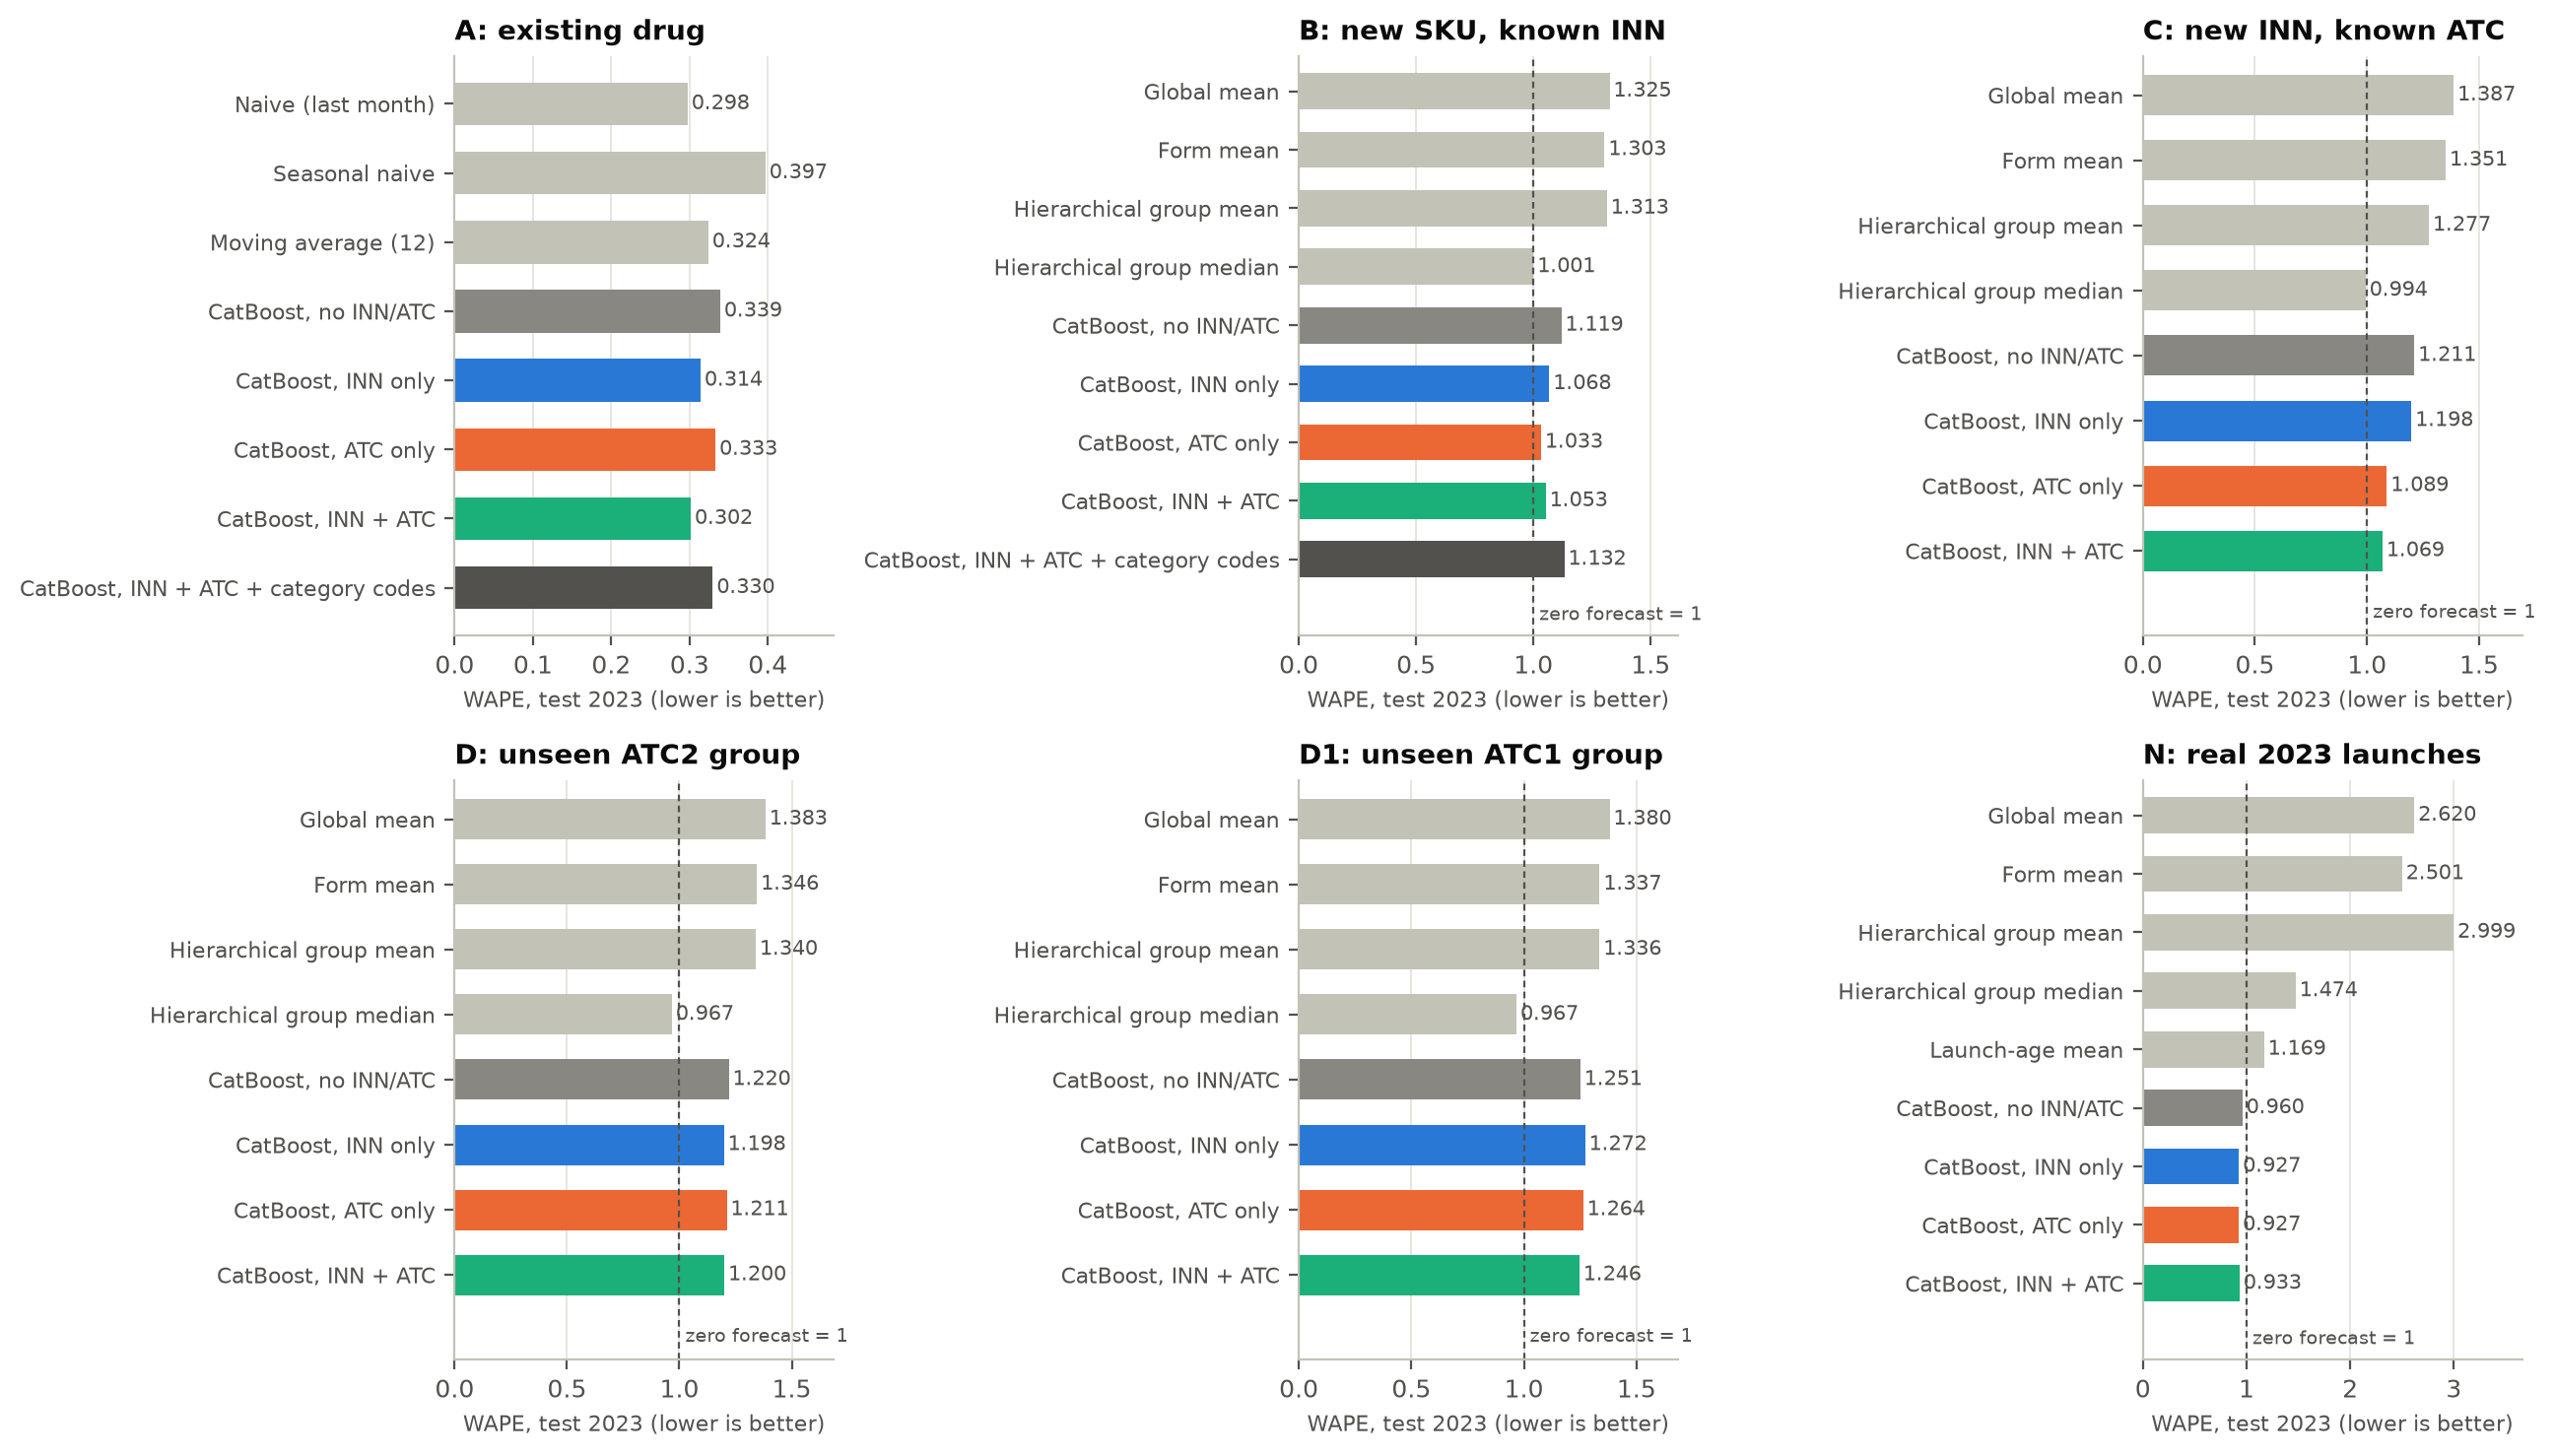

In [6]:
F("res_overview_wape")

In [7]:
T("wape_fold_spread").query("model.str.startswith('catboost')").round(3)

,scenario,model,mean,std,min,max
0,A,catboost_atc,0.333,NaN,0.333,0.333
1,A,catboost_both,0.302,NaN,0.302,0.302
2,A,catboost_both_codes,0.330,NaN,0.330,0.330
3,A,catboost_inn,0.314,NaN,0.314,0.314
4,A,catboost_none,0.339,NaN,0.339,0.339
8,B,catboost_atc,1.034,0.025,0.993,1.054
9,B,catboost_both,1.057,0.040,1.007,1.118
10,B,catboost_both_codes,1.139,0.063,1.085,1.245
11,B,catboost_inn,1.076,0.067,1.026,1.194
12,B,catboost_none,1.121,0.031,1.070,1.145


## 5. Ablation: contribution of INN and ATC

Relative WAPE change of each arm against the CatBoost model without INN/ATC (negative = better). 95% intervals from a paired cluster bootstrap (1,000 resamples) over SKUs (A, N), twin clusters (B), INN units (C), ATC2 groups (D) or ATC1 groups (D1).

In [8]:
abl = T("ablation_inn_atc")
abl[["scenario", "arm", "WAPE", "MAE", "RMSE", "rel_vs_none", "rel_vs_none_lo", "rel_vs_none_hi",
     "best_baseline", "baseline_WAPE", "rel_vs_baseline", "clusters"]].round(3)

,scenario,arm,WAPE,MAE,RMSE,rel_vs_none,rel_vs_none_lo,rel_vs_none_hi,best_baseline,baseline_WAPE,rel_vs_baseline,clusters
0,A,none,0.339,2279.503,13019.852,0.000,0.000,0.000,naive,0.298,0.140,10381
1,A,inn,0.314,2110.808,13542.434,-0.074,-0.117,-0.015,naive,0.298,0.056,10381
2,A,atc,0.333,2239.049,17968.883,-0.018,-0.112,0.108,naive,0.298,0.120,10381
3,A,both,0.302,2026.912,12358.853,-0.111,-0.163,-0.052,naive,0.298,0.014,10381
4,A,both_codes,0.330,2216.060,15397.833,-0.028,-0.109,0.075,naive,0.298,0.108,10381
5,B,none,1.119,8252.242,32524.556,0.000,0.000,0.000,hierarchical_median,1.001,0.118,7565
6,B,inn,1.068,7876.606,31857.288,-0.046,-0.067,-0.027,hierarchical_median,1.001,0.068,7565
7,B,atc,1.033,7615.181,32043.874,-0.077,-0.091,-0.064,hierarchical_median,1.001,0.032,7565
8,B,both,1.053,7761.781,31827.365,-0.059,-0.076,-0.044,hierarchical_median,1.001,0.052,7565
9,B,both_codes,1.132,8345.782,31766.799,0.011,-0.007,0.031,hierarchical_median,1.001,0.131,7565


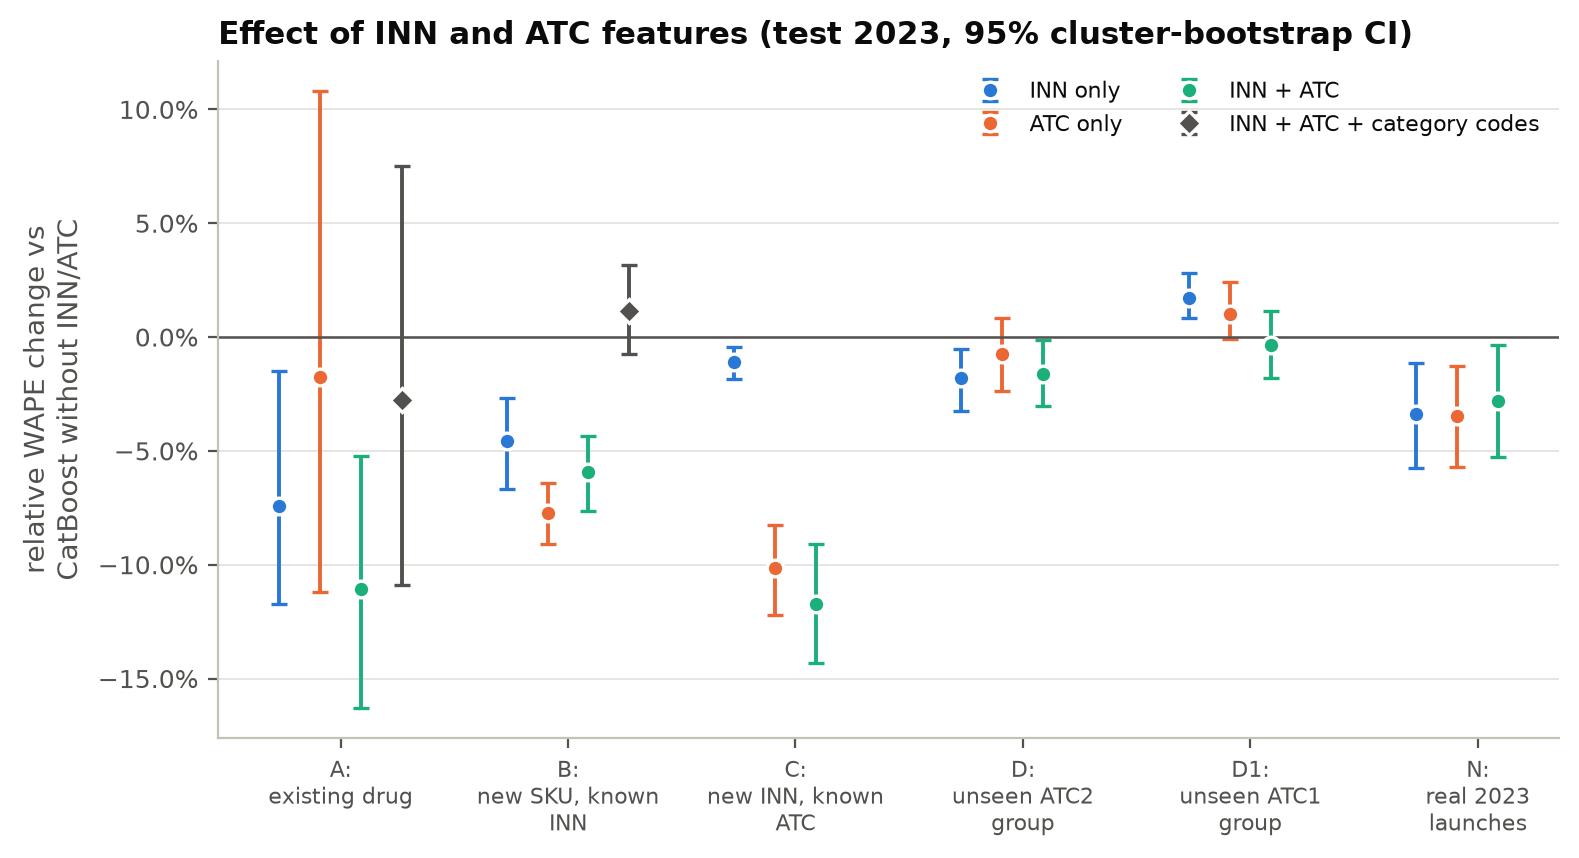

In [9]:
F("res_ablation_inn_atc")

## 6. Actual vs predicted

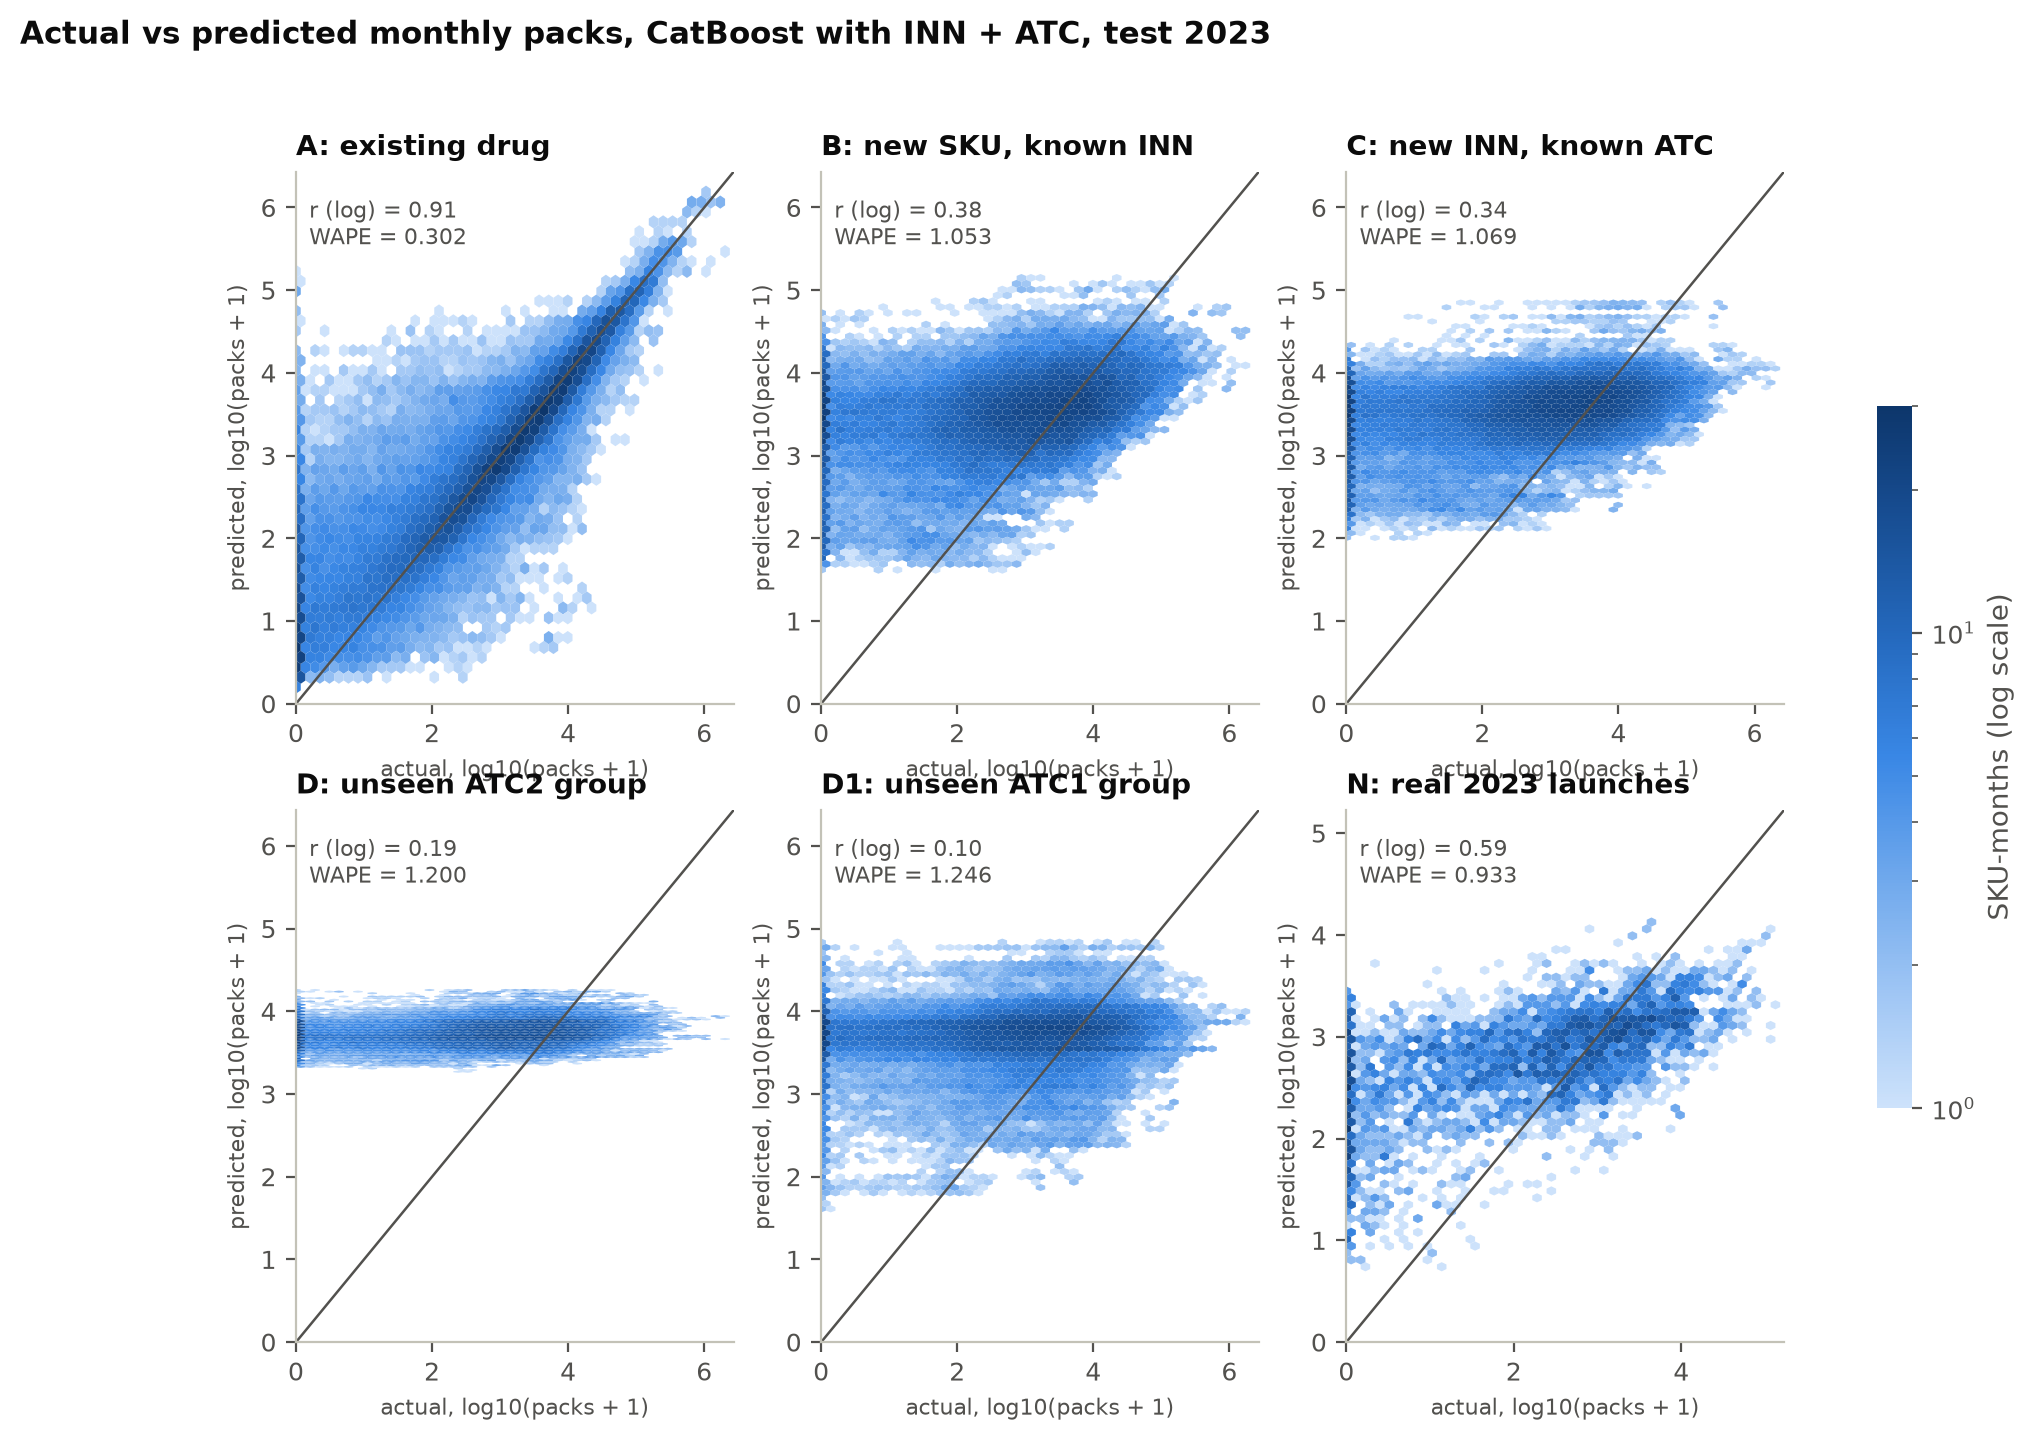

In [10]:
F("res_actual_vs_predicted")

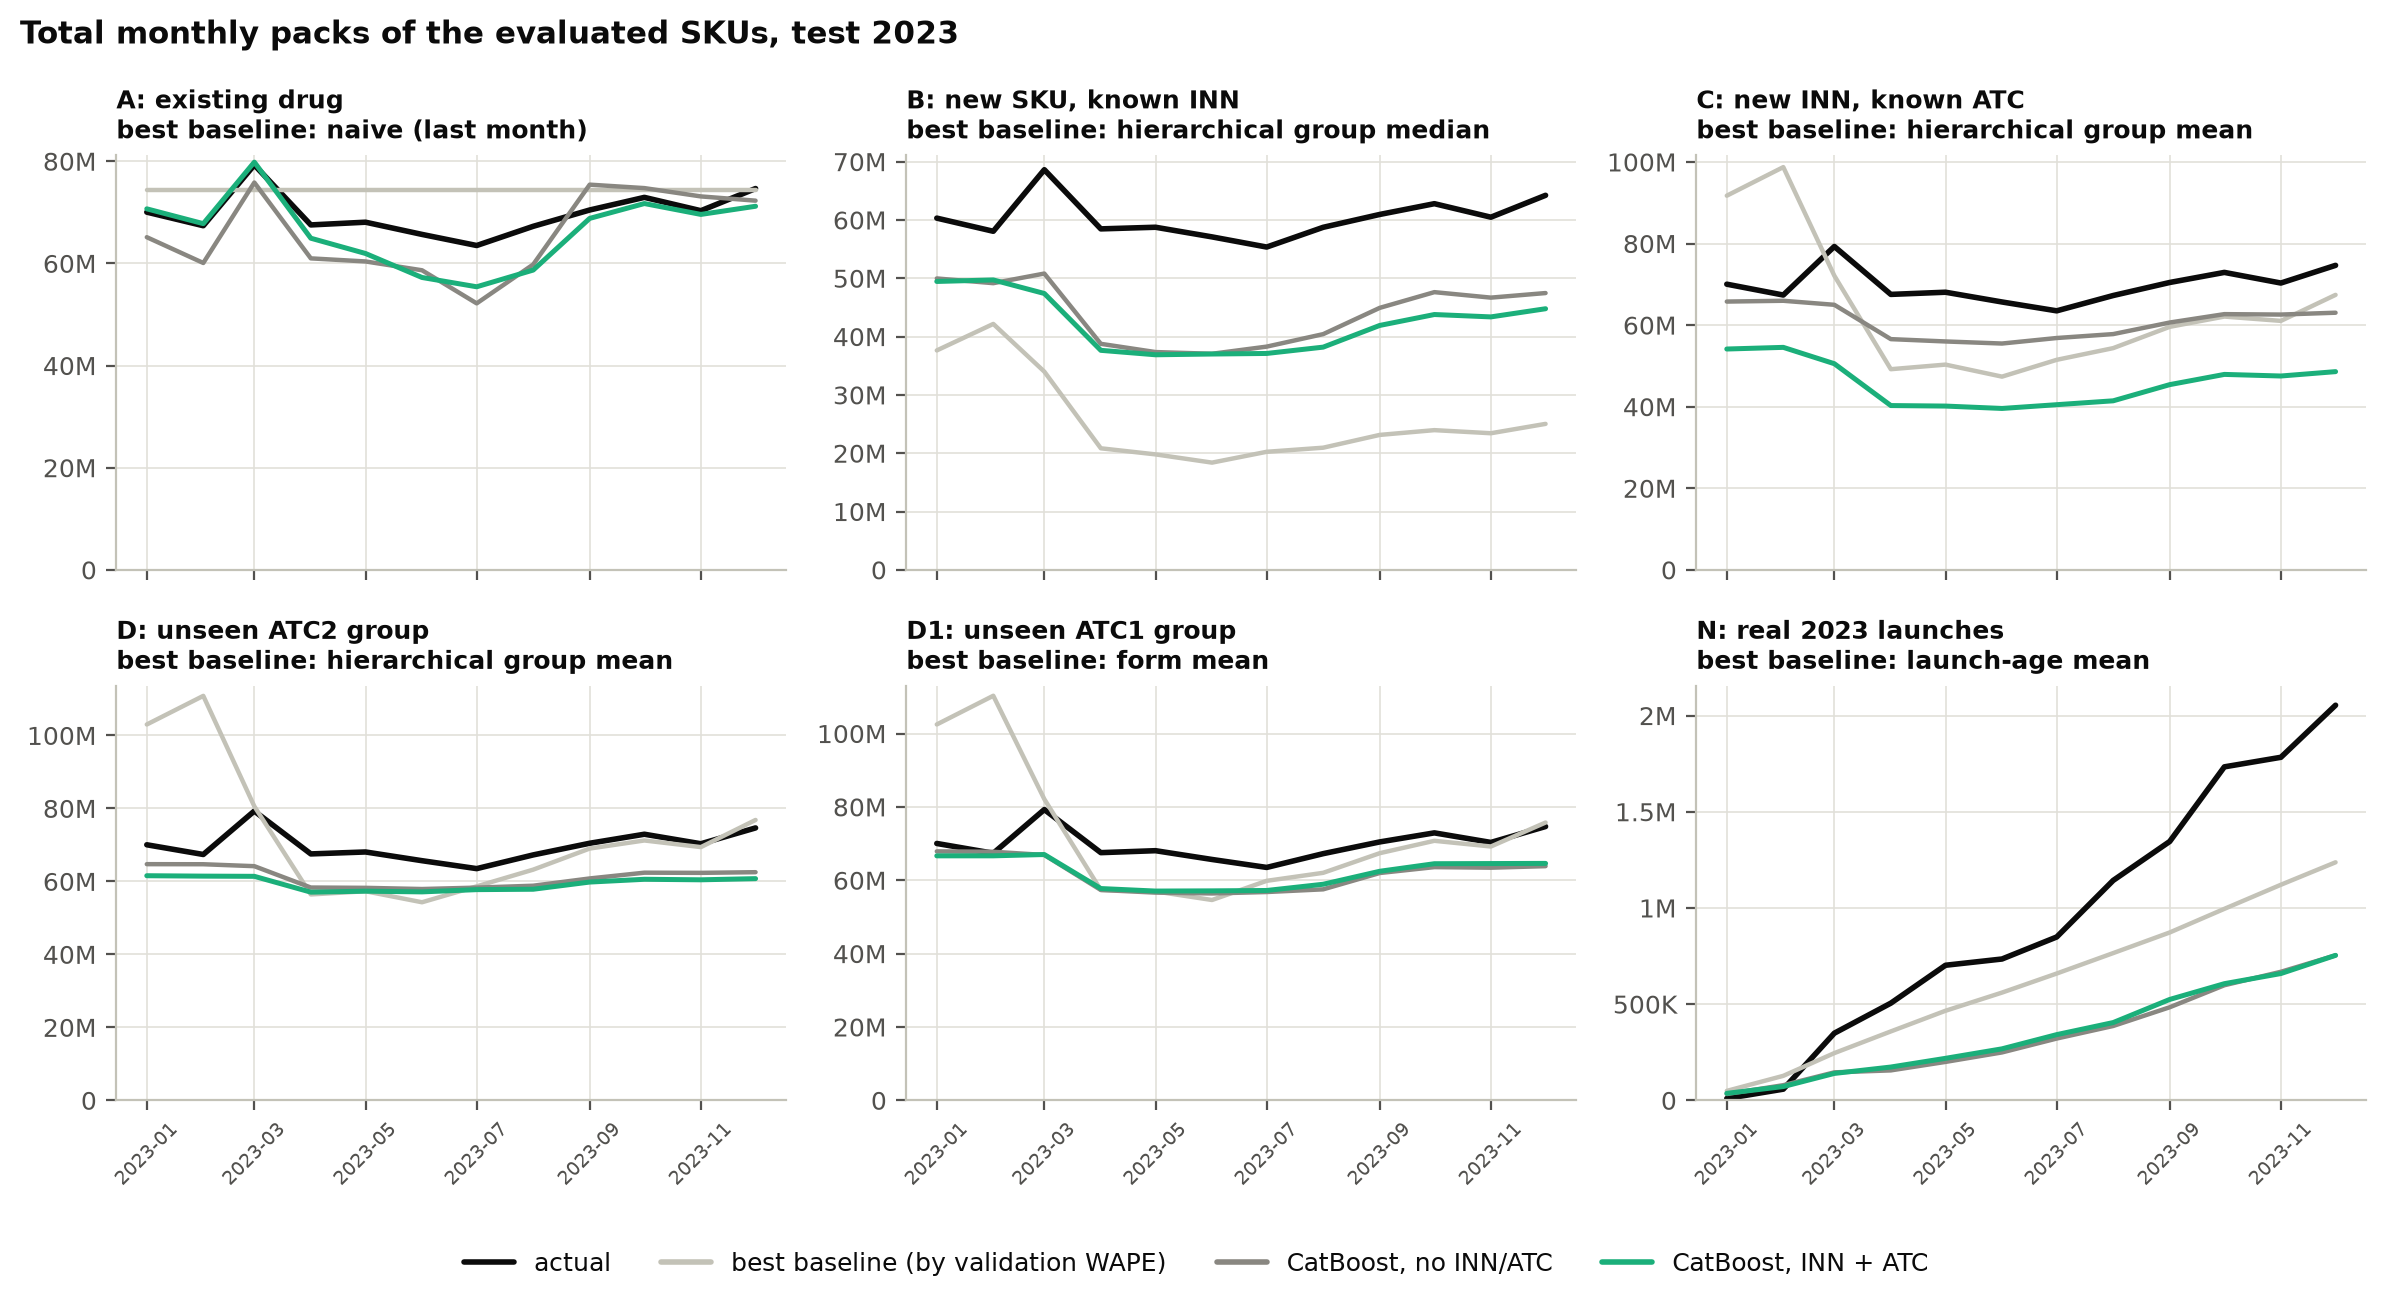

In [11]:
F("res_aggregate_test_2023")

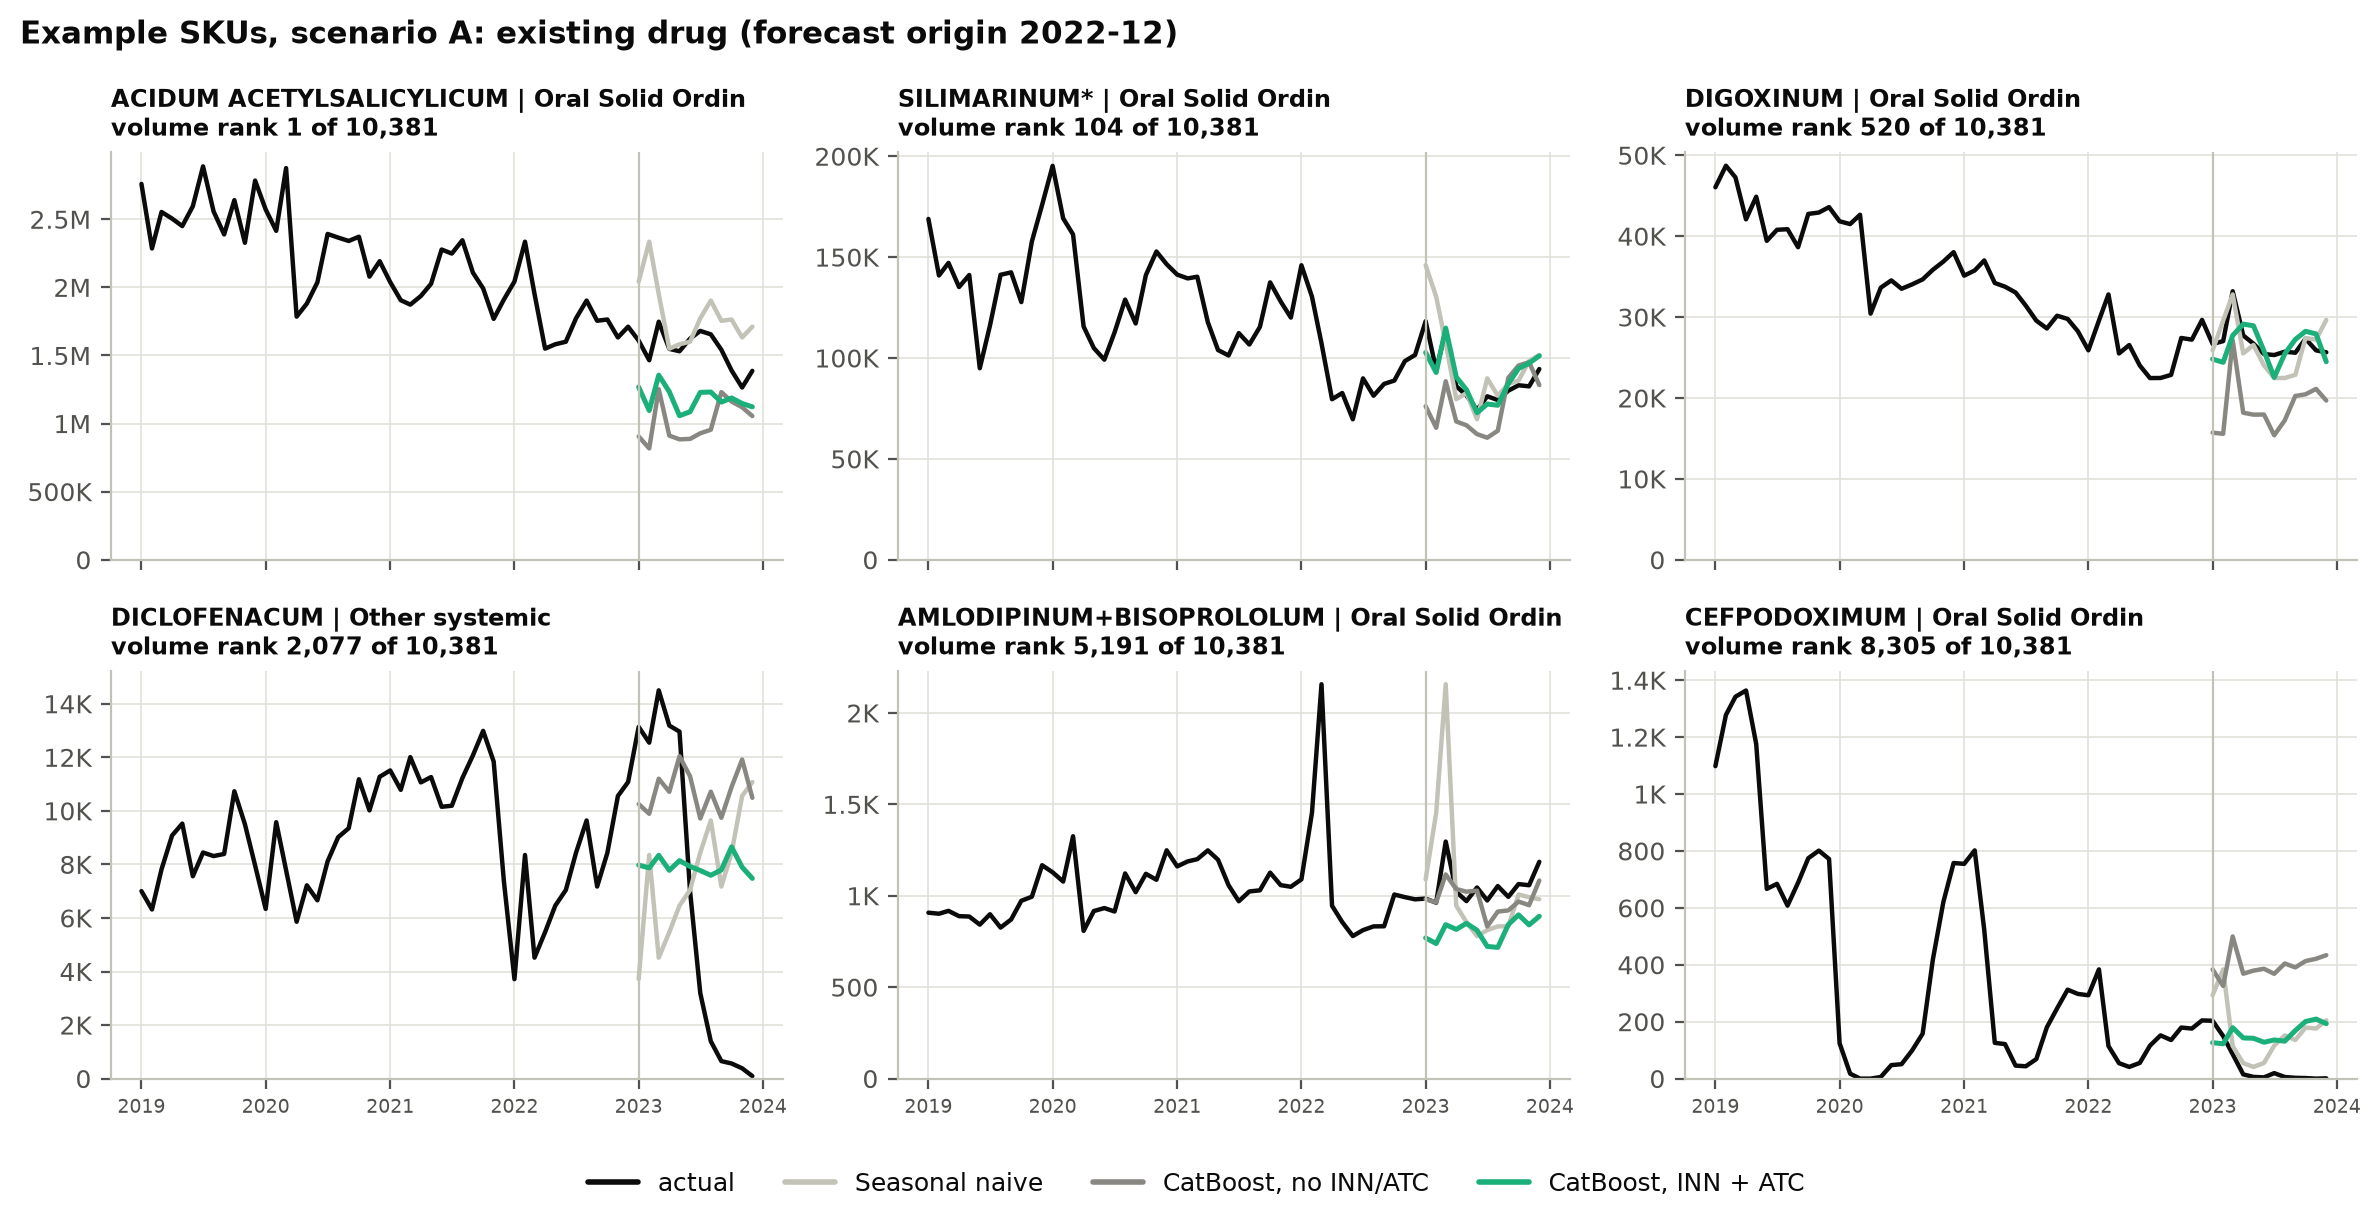

In [12]:
F("res_examples_existing")

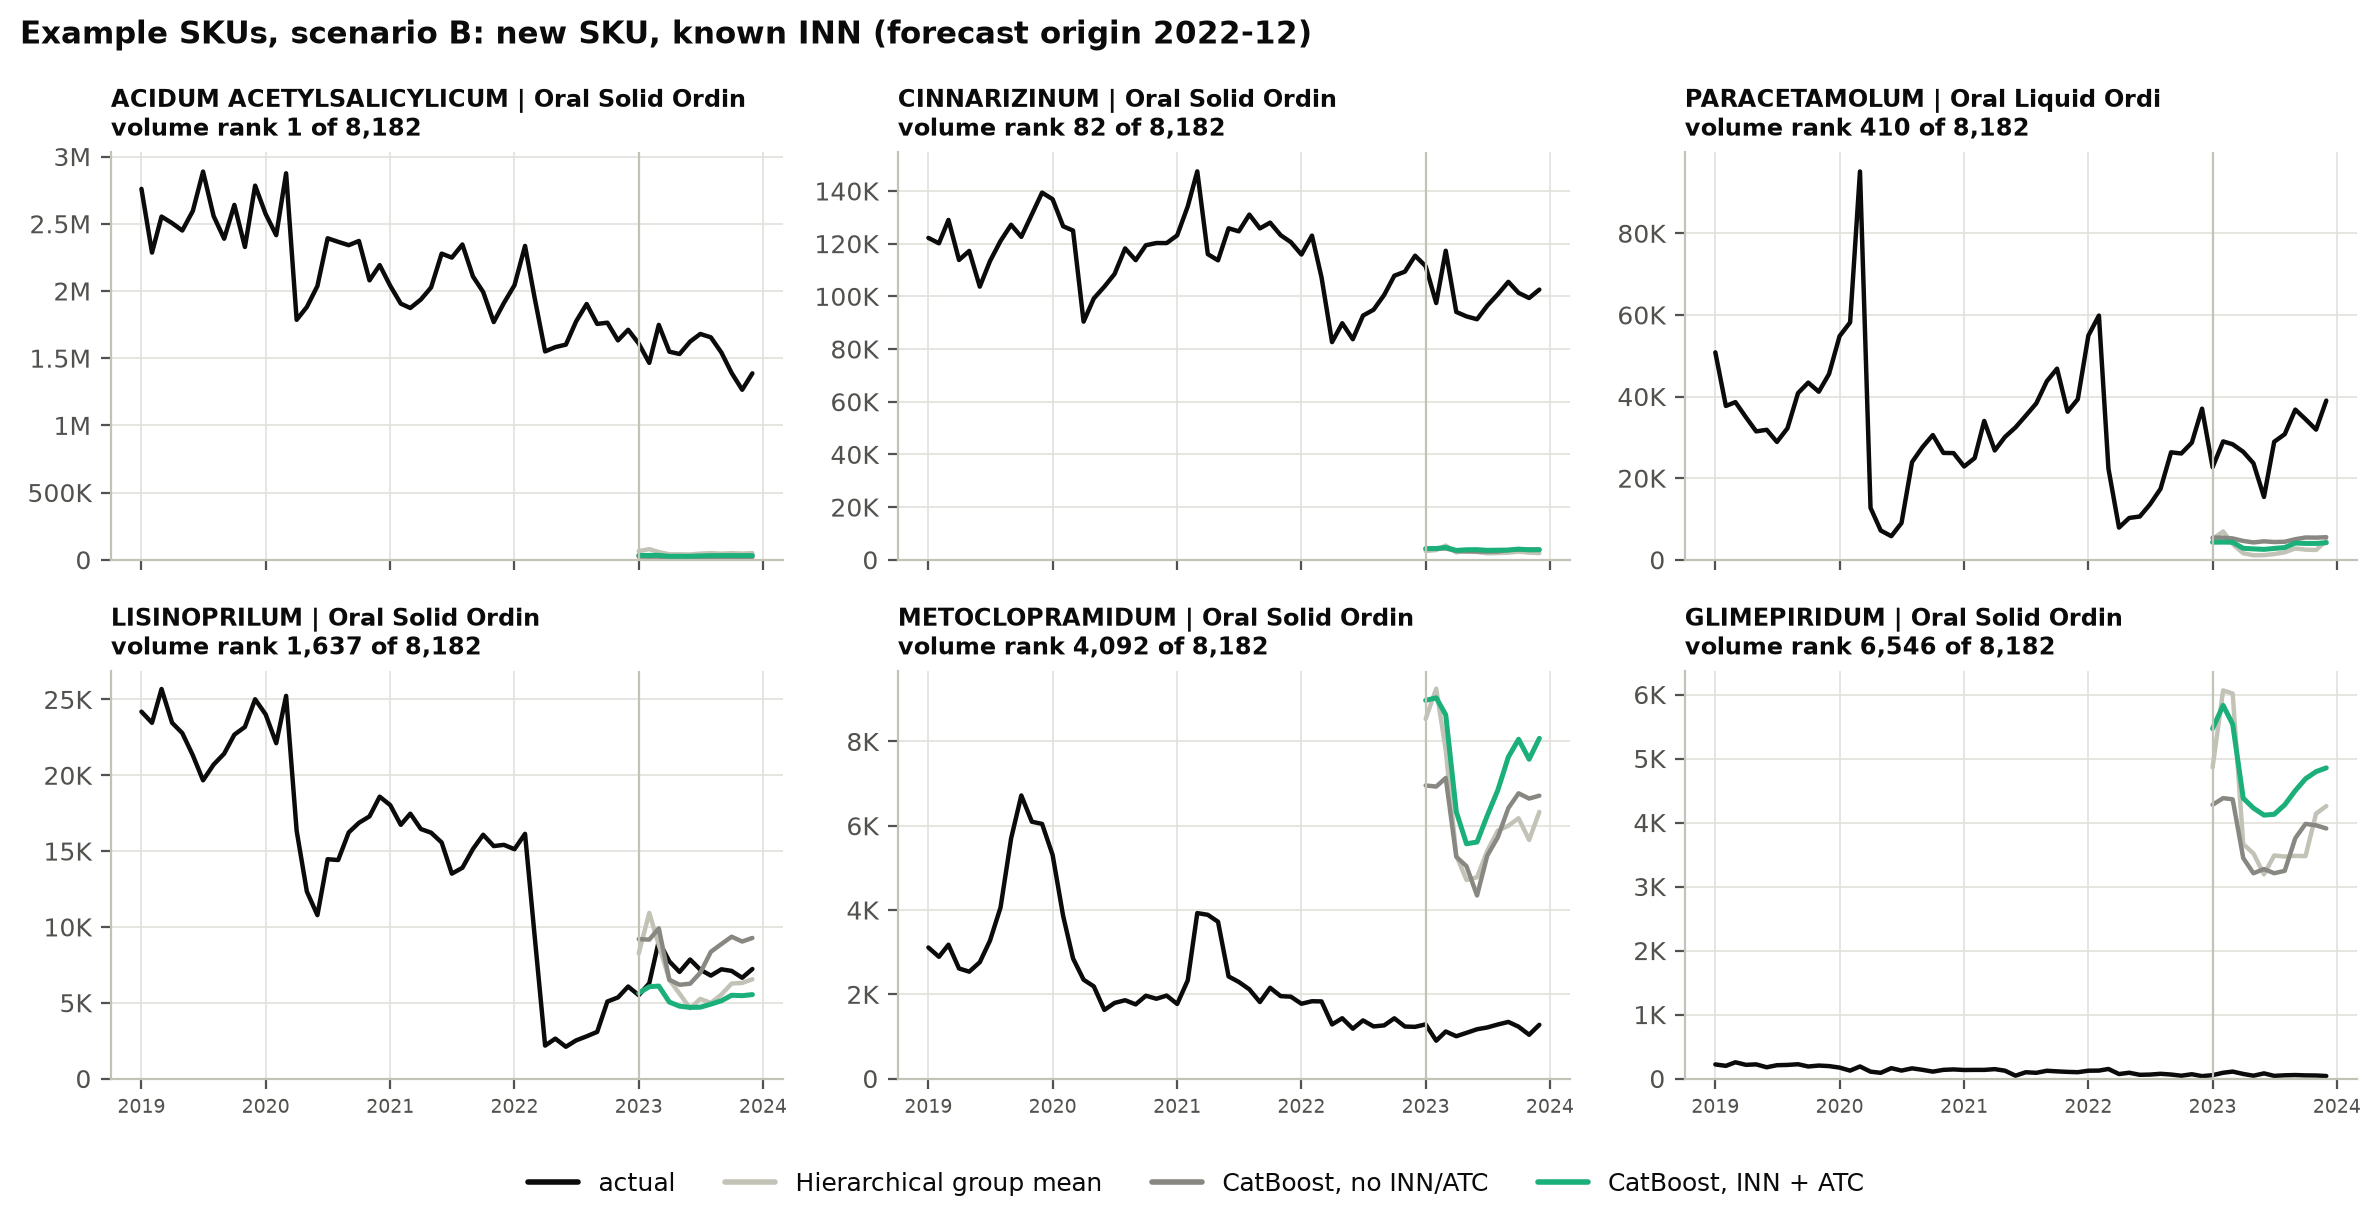

In [13]:
F("res_examples_new_sku")

## 7. Error analysis

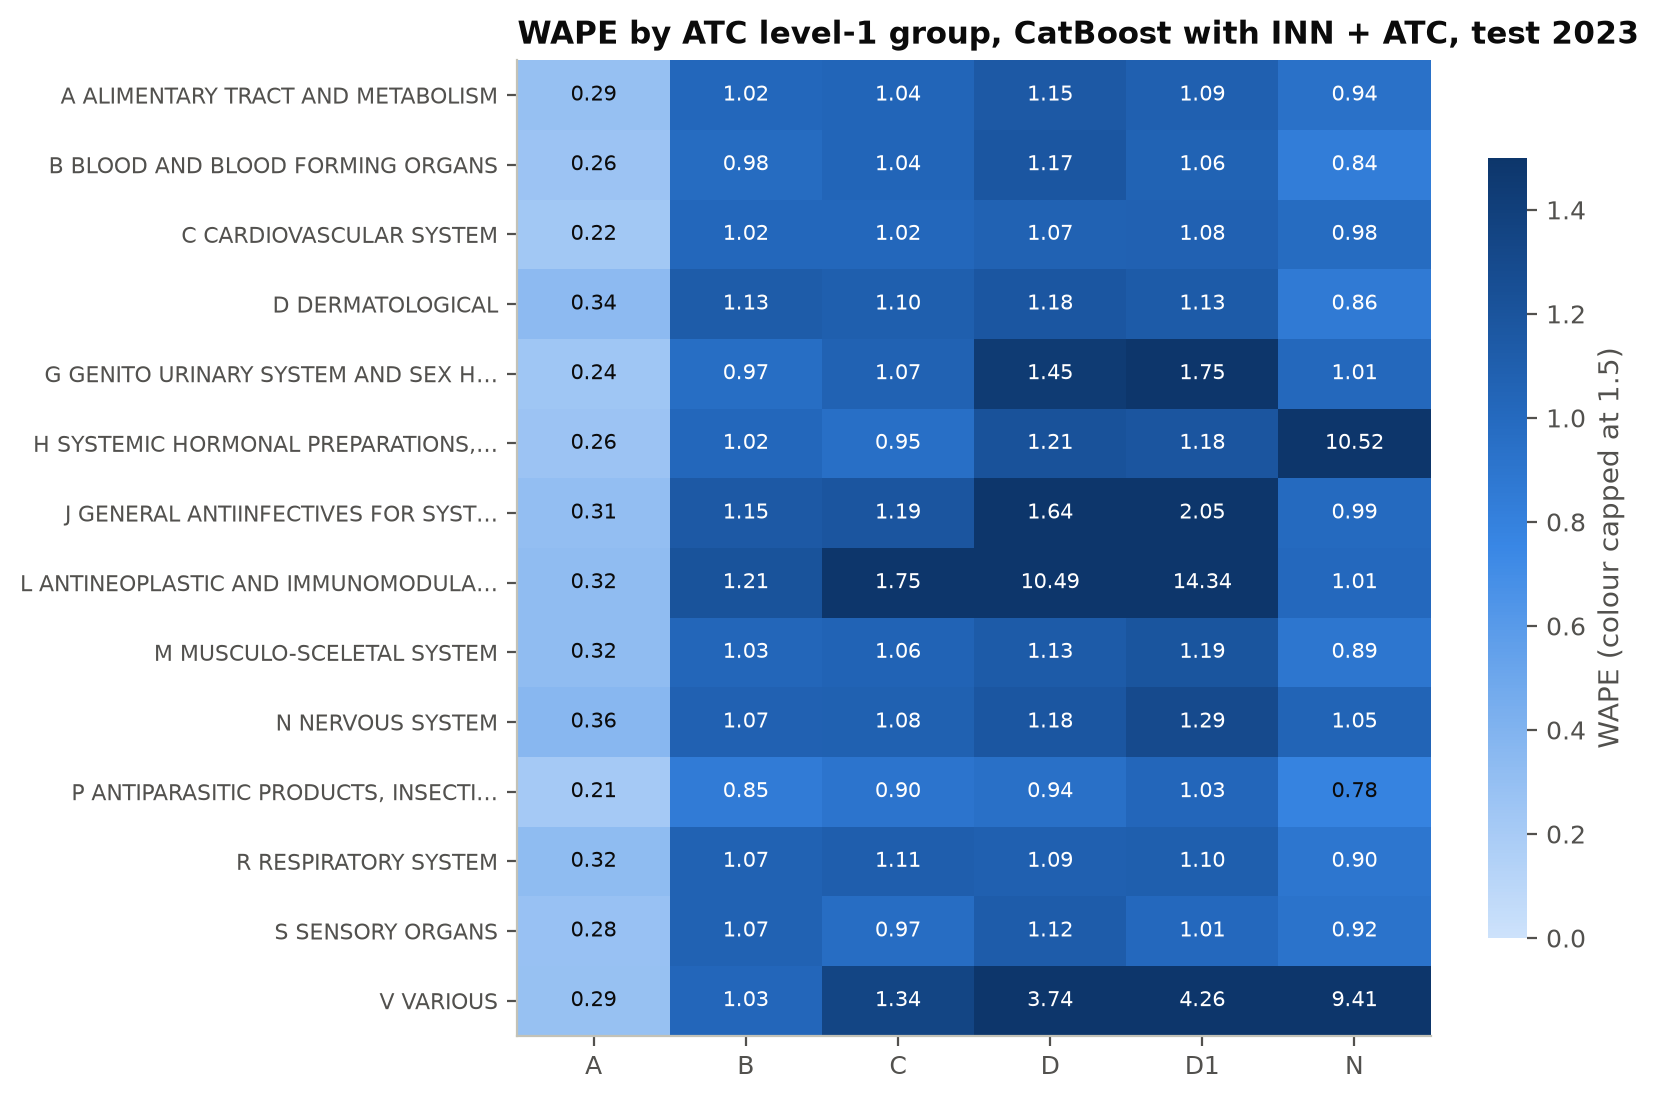

In [14]:
F("res_error_by_atc1")

In [15]:
br = T("error_breakdowns")
br.query("breakdown == 'volume_quintile'").pivot_table(index=["scenario", "group"], columns="model", values="WAPE").round(3)

model                   catboost_both  catboost_none  form_mean  \
scenario group                                                    
A        Q1 (smallest)         12.481         12.508        NaN   
         Q2                     0.918          1.121        NaN   
         Q3                     0.493          0.568        NaN   
         Q4                     0.386          0.407        NaN   
         Q5 (largest)           0.275          0.312        NaN   
B        Q1 (smallest)        288.953        348.970        NaN   
         Q2                    12.949         15.748        NaN   
         Q3                     2.972          3.117        NaN   
         Q4                     0.857          0.878        NaN   
         Q5 (largest)           0.794          0.817        NaN   
C        Q1 (smallest)        455.701        751.395        NaN   
         Q2                    15.551         23.266        NaN   
         Q3                     2.870          4.245        NaN   
         Q4                     0.687          0.756        NaN   
         Q5 (largest)           0.821          0.790        NaN   
D        Q1 (smallest)        739.861        783.664        NaN   
         Q2                    22.929         23.416        NaN   
         Q3                     4.129          4.281        NaN   
         Q4                     0.708          0.735        NaN   
         Q5 (largest)           0.793          0.792        NaN   
D1       Q1 (smallest)        776.794        790.196    894.208   
         Q2                    23.564         23.494     28.631   
         Q3                     4.340          4.370      5.364   
         Q4                     0.897          0.869      1.097   
         Q5 (largest)           0.800          0.805      0.770   
N        Q1 (smallest)        281.820        424.135        NaN   
         Q2                    17.028         20.889        NaN   
         Q3                     2.738          3.083        NaN   
         Q4                     0.912          0.742        NaN   
         Q5 (largest)           0.847          0.868        NaN   

model                   hierarchical_mean  hierarchical_median  \
scenario group                                                   
A        Q1 (smallest)                NaN                  NaN   
         Q2                           NaN                  NaN   
         Q3                           NaN                  NaN   
         Q4                           NaN                  NaN   
         Q5 (largest)                 NaN                  NaN   
B        Q1 (smallest)                NaN              170.551   
         Q2                           NaN                6.991   
         Q3                           NaN                1.963   
         Q4                           NaN                0.846   
         Q5 (largest)                 NaN                0.869   
C        Q1 (smallest)            668.919                  NaN   
         Q2                        22.678                  NaN   
         Q3                         4.457                  NaN   
         Q4                         1.262                  NaN   
         Q5 (largest)               0.816                  NaN   
D        Q1 (smallest)            855.643                  NaN   
         Q2                        29.241                  NaN   
         Q3                         5.525                  NaN   
         Q4                         1.083                  NaN   
         Q5 (largest)               0.774                  NaN   
D1       Q1 (smallest)                NaN                  NaN   
         Q2                           NaN                  NaN   
         Q3                           NaN                  NaN   
         Q4                           NaN                  NaN   
         Q5 (largest)                 NaN                  NaN   
N        Q1 (smallest)                NaN                  NaN   
       

In [16]:
br.query("breakdown == 'nfc' and model == 'catboost_both'").pivot_table(index="group", columns="scenario", values="WAPE").round(2)

scenario,A,B,C,D,D1,N
group,,,,,,
Lung Administration,0.24,1.03,1.08,1.47,1.14,1.55
Nasal Topical,0.28,1.03,1.11,0.94,0.94,0.83
Nasal systemic,0.28,0.88,0.71,1.17,1.29,NaN
Non-Human Use and Others,1.67,3.00,2.27,2.30,1.61,33.45
Ophthalmic,0.28,1.08,1.00,1.17,1.05,0.90
Oral Liquid Ordinary,0.33,1.07,1.08,1.25,1.18,1.01
Oral Solid Ordinary,0.30,1.04,1.04,1.13,1.26,0.95
Oral Solid Retard,0.27,0.97,1.03,1.22,1.25,3.53
Oral Topical,0.40,1.06,1.03,1.06,1.06,0.91


### Scenario C: which new INNs are forecast better?

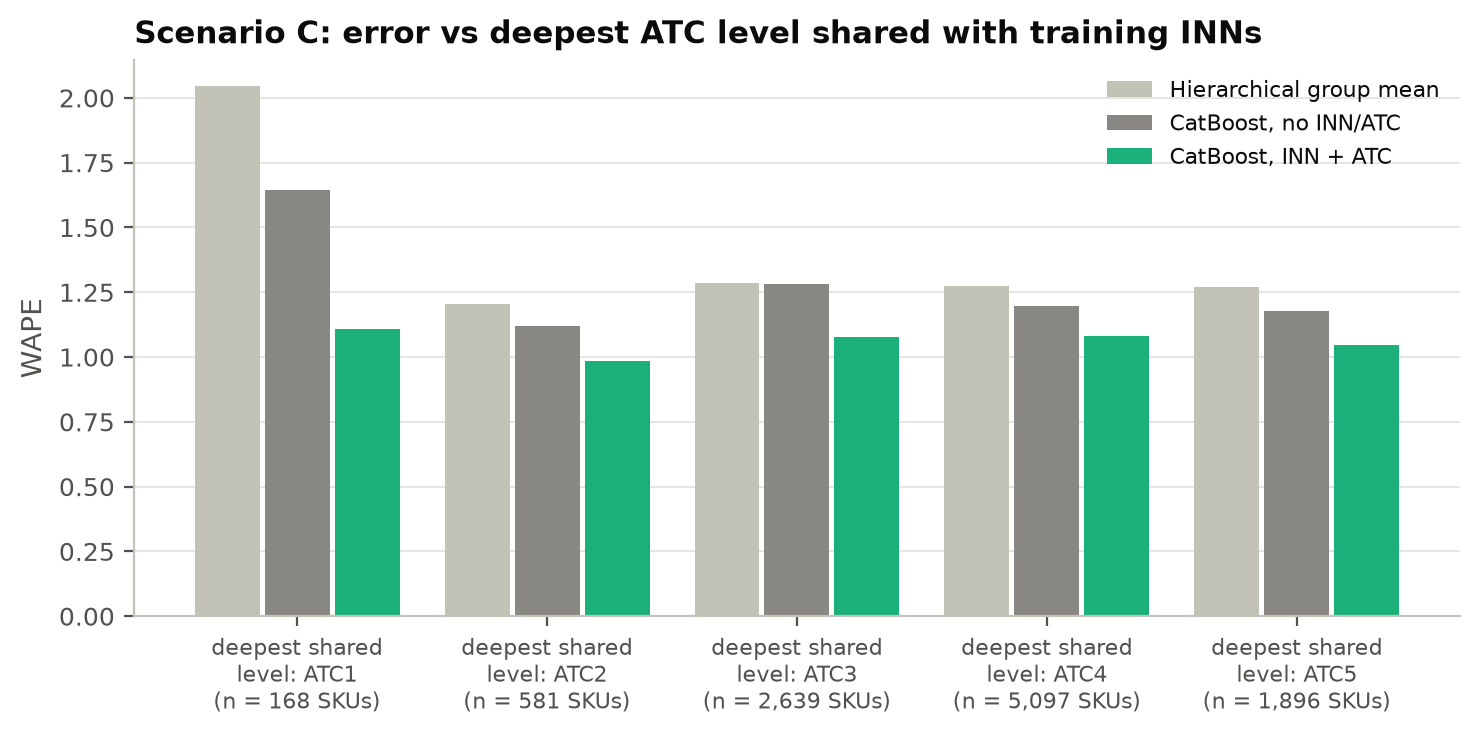

WAPE                                             n  \
model catboost_both catboost_none hierarchical_mean catboost_both   
group                                                               
1             1.107         1.645             2.044        2016.0   
2             0.986         1.120             1.204        6972.0   
3             1.079         1.280             1.285       31668.0   
4             1.082         1.198             1.273       61164.0   
5             1.046         1.178             1.269       22752.0   

                                       
model catboost_none hierarchical_mean  
group                                  
1            2016.0            2016.0  
2            6972.0            6972.0  
3           31668.0           31668.0  
4           61164.0           61164.0  
5           22752.0           22752.0

In [17]:
F("res_c_known_atc_depth")
br.query("scenario == 'C' and breakdown == 'known_atc_depth'").pivot_table(index="group", columns="model", values=["WAPE", "n"]).round(3)

### Real 2023 launches (scenario N)

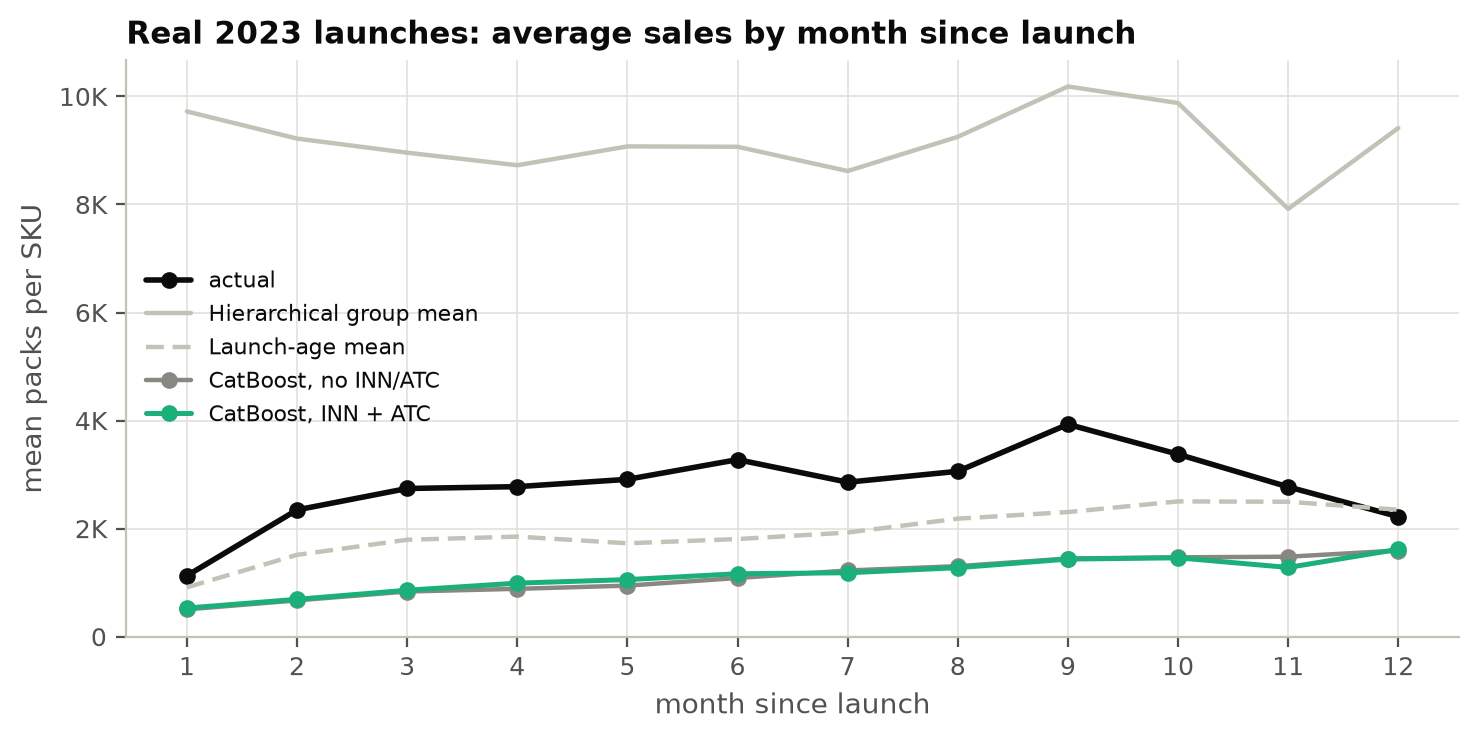

WAPE                \
model                                 catboost_both catboost_none   
breakdown group                                                     
inn_seen  INN sold before 2023                0.930         0.949   
          new INN                             0.963         1.088   
          no INN                              1.078         1.450   
twin      has an older identical twin         0.883         0.912   
          no older twin                       0.965         0.991   

                                                                  n  \
model                                 launch_age_mean catboost_both   
breakdown group                                                       
inn_seen  INN sold before 2023                  1.135        3847.0   
          new INN                               1.800         113.0   
          no INN                                2.630         299.0   
twin      has an older identical twin           0.967         871.0   
          no older twin                         1.301        3388.0   

                                                                     
model                                 catboost_none launch_age_mean  
breakdown group                                                      
inn_seen  INN sold before 2023               3847.0          3847.0  
          new INN                             113.0           113.0  
          no INN                              299.0           299.0  
twin      has an older identical twin         871.0           871.0  
          no older twin                      3388.0          3388.0

In [18]:
F("res_launch_age")
br.query("scenario == 'N' and breakdown in ['inn_seen', 'twin']").pivot_table(index=["breakdown", "group"], columns="model", values=["WAPE", "n"]).round(3)

### Largest INN-level errors

In [19]:
for s in ("A", "B", "C", "N"):
    display(Markdown(f"**Scenario {s}**"))
    display(T(f"inn_errors_{s}").round(3).head(10))

**Scenario A**

,inn,skus,actual,predicted,abs_error,WAPE,share_of_total_error
0,ACIDUM ACETYLSALICYLICUM*+COFFEINUM*+PARACETAMOLUM,33,3.613274e+07,3.735942e+07,1.177775e+07,0.326,0.047
1,ACIDUM ACETYLSALICYLICUM*,43,2.222851e+07,1.794704e+07,1.168480e+07,0.526,0.046
2,PARACETAMOLUM,39,1.147725e+07,1.952469e+07,8.301726e+06,0.723,0.033
3,(no INN),656,1.962357e+07,1.831302e+07,5.592611e+06,0.285,0.022
4,IBUPROFENUM,97,1.313011e+07,1.111645e+07,5.101776e+06,0.389,0.020
5,XYLOMETAZOLINUM,43,1.695563e+07,1.614886e+07,4.821014e+06,0.284,0.019
6,NATRII CHLORIDUM*,63,1.544530e+07,1.342429e+07,4.790115e+06,0.310,0.019
7,OMEPRAZOLUM,31,6.390695e+06,5.609974e+06,4.186812e+06,0.655,0.017
8,SPIRITUS AETHYLICUS*,56,9.278356e+06,8.438940e+06,3.713032e+06,0.400,0.015
9,DICLOFENACUM,100,1.145182e+07,1.014540e+07,3.657895e+06,0.319,0.014


**Scenario B**

,inn,skus,actual,predicted,abs_error,WAPE,share_of_total_error
0,ACIDUM ACETYLSALICYLICUM*+COFFEINUM*+PARACETAMOLUM,33,3.613274e+07,1.644776e+07,3.888329e+07,1.076,0.051
1,ACIDUM ACETYLSALICYLICUM*,43,2.222851e+07,7.010286e+06,2.260727e+07,1.017,0.030
2,XYLOMETAZOLINUM,43,1.695563e+07,1.053506e+07,1.829147e+07,1.079,0.024
3,NATRII CHLORIDUM*,63,1.544530e+07,7.766193e+06,1.584244e+07,1.026,0.021
4,ASCORBIC ACID,41,1.446136e+07,8.437036e+06,1.491779e+07,1.032,0.020
5,METAMIZOLUM NATRICUM,18,1.300126e+07,2.425183e+06,1.408207e+07,1.083,0.018
6,IBUPROFENUM,97,1.313011e+07,9.022179e+06,1.313103e+07,1.000,0.017
7,SPIRITUS AETHYLICUS*,56,9.278356e+06,8.922504e+06,1.307765e+07,1.409,0.017
8,PARACETAMOLUM,39,1.147725e+07,5.333652e+06,1.307284e+07,1.139,0.017
9,DICLOFENACUM,100,1.145182e+07,8.668382e+06,1.114708e+07,0.973,0.015


**Scenario C**

,inn,skus,actual,predicted,abs_error,WAPE,share_of_total_error
0,ACIDUM ACETYLSALICYLICUM*+COFFEINUM*+PARACETAMOLUM,33,3.613274e+07,3.264977e+06,3.492204e+07,0.966,0.039
1,(no INN),656,1.962357e+07,1.836950e+07,2.329539e+07,1.187,0.026
2,XYLOMETAZOLINUM,43,1.695563e+07,1.860447e+07,2.309247e+07,1.362,0.026
3,ACIDUM ACETYLSALICYLICUM*,43,2.222851e+07,2.999829e+06,2.179033e+07,0.980,0.024
4,NATRII CHLORIDUM*,63,1.544530e+07,2.530435e+06,1.489521e+07,0.964,0.017
5,ASCORBIC ACID,41,1.446136e+07,2.893783e+06,1.397709e+07,0.967,0.016
6,METAMIZOLUM NATRICUM,18,1.300126e+07,1.401016e+06,1.292354e+07,0.994,0.014
7,IBUPROFENUM,97,1.313011e+07,7.576866e+06,1.249050e+07,0.951,0.014
8,PARACETAMOLUM,39,1.147725e+07,2.745913e+06,1.120735e+07,0.976,0.013
9,DICLOFENACUM,100,1.145182e+07,6.338307e+06,1.070541e+07,0.935,0.012


**Scenario N**

,inn,skus,actual,predicted,abs_error,WAPE,share_of_total_error
0,BENZOCAINUM+MENTHOLUM*+PROCAINUM,4,842134.336,48668.261,799844.461,0.950,0.076
1,NIMESULIDUM,8,639960.239,82174.302,578116.064,0.903,0.055
2,PARACETAMOLUM,7,538171.009,216665.186,550408.922,1.023,0.052
3,OXYMETAZOLINUM,3,627535.194,102619.643,528792.997,0.843,0.050
4,XYLOMETAZOLINUM,4,605598.231,118002.326,498314.556,0.823,0.047
5,CINCHOCAINUM+DEQUALINII CHLORIDUM,3,442882.497,21827.451,449507.866,1.015,0.043
6,RANITIDINUM,2,429113.831,36439.265,394566.126,0.919,0.038
7,DIOSMINUM+HESPERIDINUM,1,321930.658,12770.131,309160.527,0.960,0.029
8,CHLOROBUTANOLUM+CHOLINI SALICYLAS+HEXETIDINUM,6,333384.371,56734.393,285131.609,0.855,0.027
9,METAMIZOLUM NATRICUM+PITOFENONUM+FENPIVERINII BROMIDUM,3,312290.601,40852.962,283472.385,0.908,0.027


## 8. Feature importance

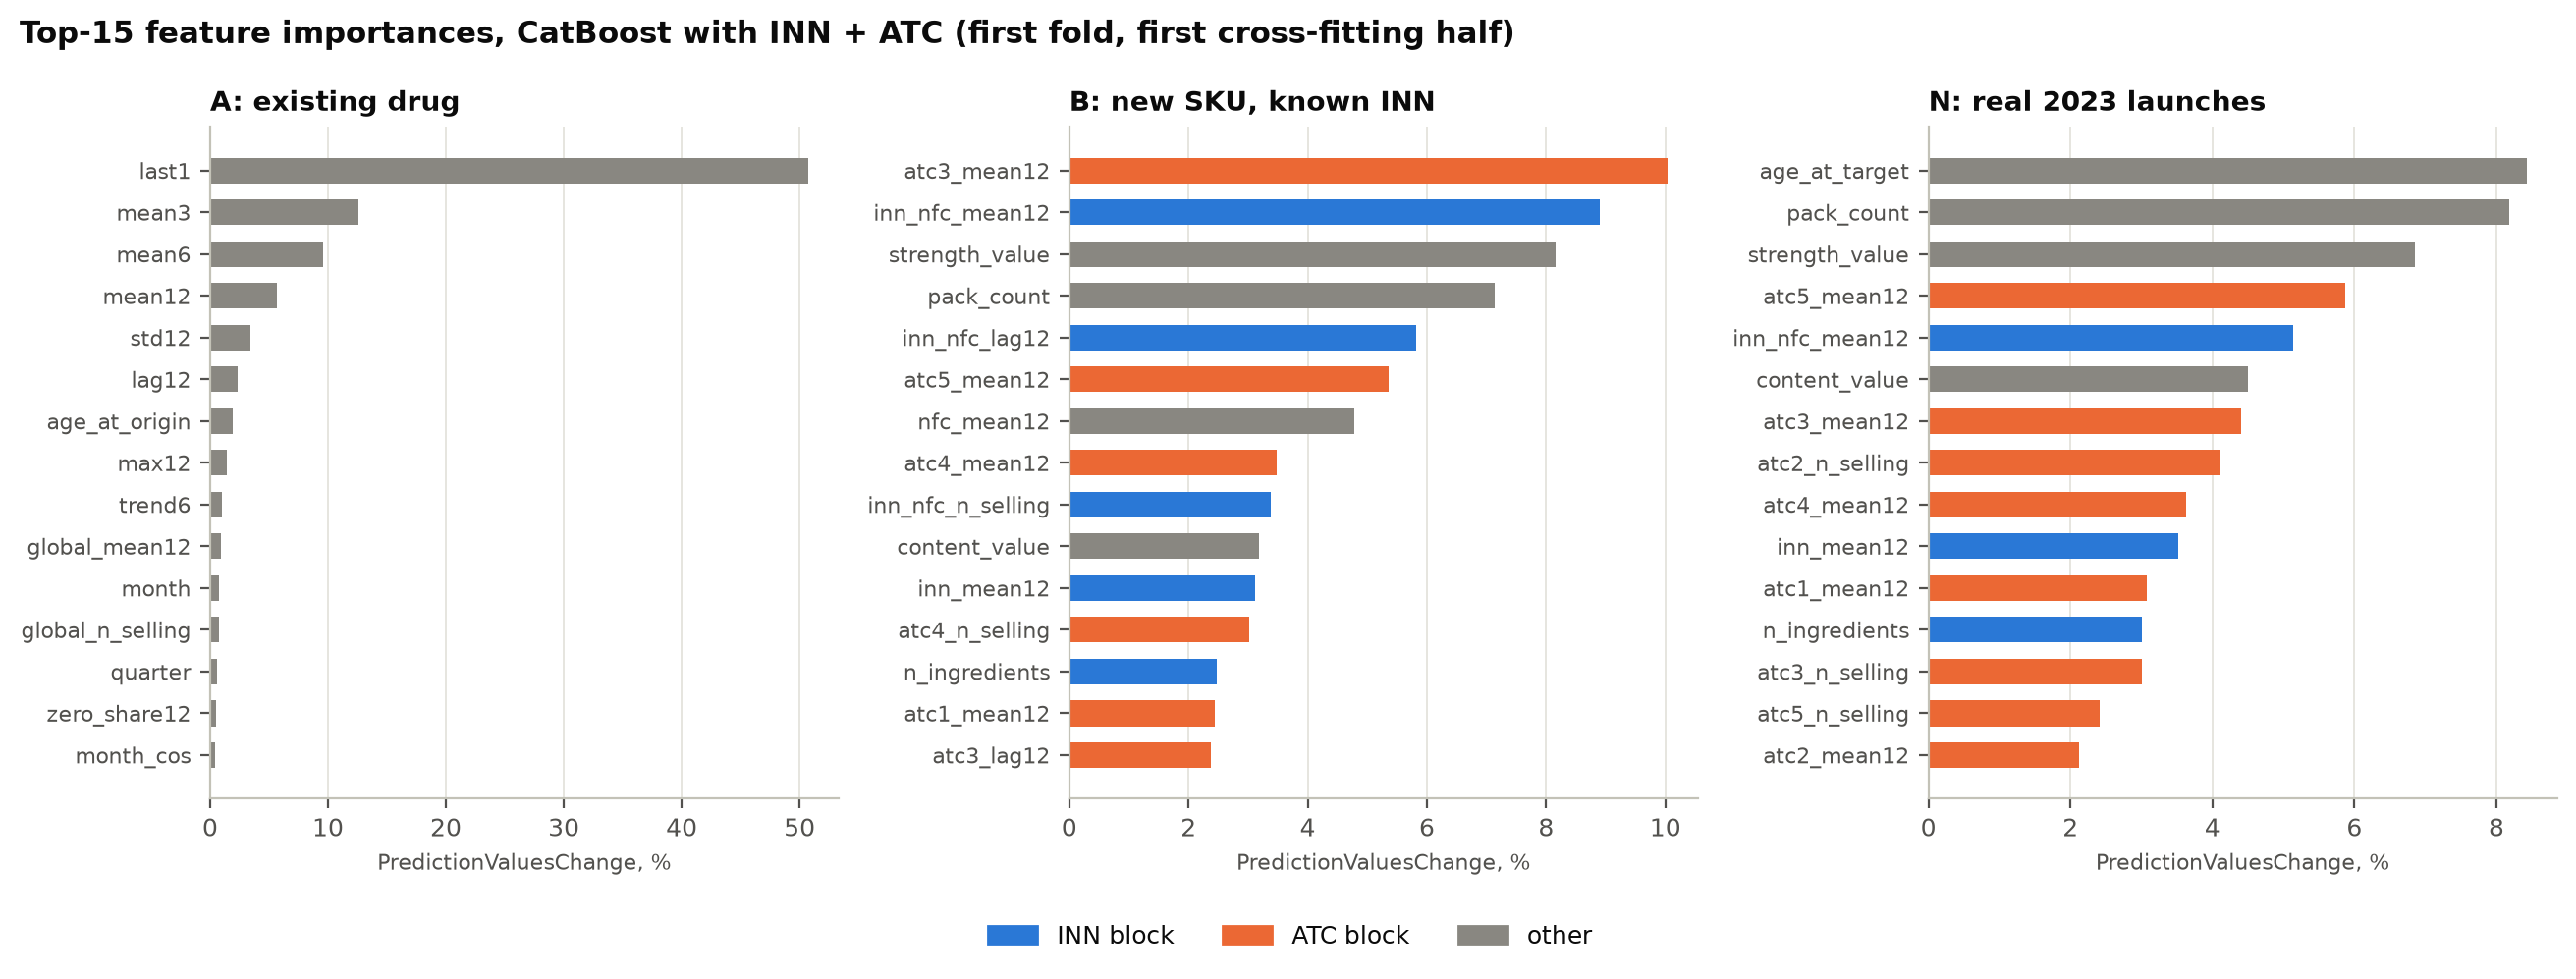

In [20]:
F("res_feature_importance")

## 9. Robustness to the number of trees and the seed

Test models refitted with 1,200 trees and three seeds; WAPE read at 100–1,200 trees (first fold for cold start). Descriptive only, not used for any choice.

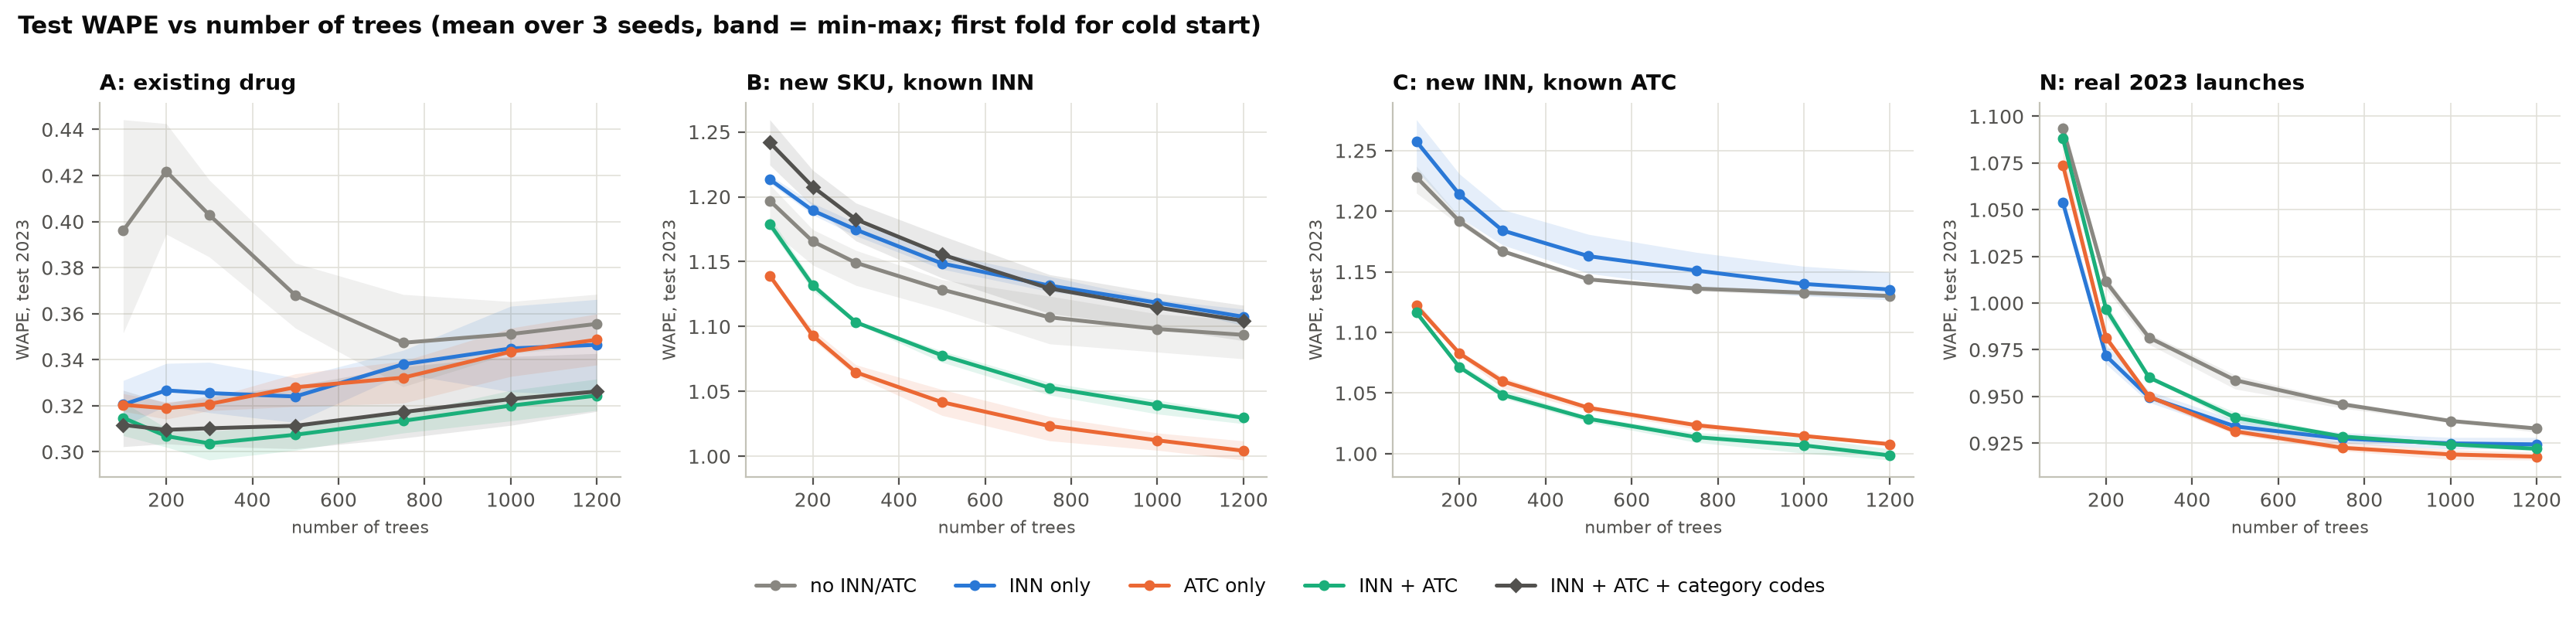

trees                 100    300    500    1000   1200
scenario arm                                          
A        atc         0.320  0.321  0.328  0.344  0.349
         both        0.315  0.304  0.307  0.320  0.324
         both_codes  0.312  0.310  0.311  0.323  0.326
         inn         0.321  0.326  0.324  0.345  0.346
         none        0.396  0.403  0.368  0.351  0.356
B        atc         1.139  1.065  1.042  1.012  1.004
         both        1.179  1.103  1.078  1.039  1.030
         both_codes  1.242  1.183  1.155  1.115  1.104
         inn         1.213  1.175  1.149  1.118  1.108
         none        1.197  1.149  1.128  1.098  1.094
C        atc         1.122  1.060  1.038  1.015  1.008
         both        1.116  1.049  1.029  1.007  0.999
         inn         1.258  1.184  1.163  1.140  1.135
         none        1.228  1.167  1.144  1.133  1.130
N        atc         1.074  0.950  0.931  0.919  0.918
         both        1.088  0.960  0.939  0.924  0.922
         inn         1.054  0.950  0.934  0.925  0.924
         none        1.093  0.982  0.959  0.937  0.933

In [21]:
F("res_robustness_trees_seeds")
rs = T("robustness_summary")
rs[rs["trees"].isin([100, 300, 500, 1000, 1200])].pivot_table(index=["scenario", "arm"], columns="trees", values="mean").round(3)

## 10. Summary computed from the result tables

In [22]:
abl = T("ablation_inn_atc").set_index(["scenario", "arm"])
lines = []
for s in AN.SCENARIO_ORDER:
    if (s, "both") not in abl.index:
        continue
    b, n = abl.loc[(s, "both")], abl.loc[(s, "none")]
    sig = "significant" if b["rel_vs_none_hi"] < 0 else ("worse" if b["rel_vs_none_lo"] > 0 else "not significant")
    lines.append(f"- **{AN.SCENARIO_SHORT[s]}**: WAPE {n['WAPE']:.3f} without INN/ATC → {b['WAPE']:.3f} with INN + ATC "
                 f"({b['rel_vs_none']:+.1%}, 95% CI {b['rel_vs_none_lo']:+.1%} … {b['rel_vs_none_hi']:+.1%}, {sig}); "
                 f"best baseline {AN.MODEL_LABELS[b['best_baseline']]} {b['baseline_WAPE']:.3f}.")
display(Markdown("\n".join(lines)))

- **A: existing drug**: WAPE 0.339 without INN/ATC → 0.302 with INN + ATC (-11.1%, 95% CI -16.3% … -5.2%, significant); best baseline Naive (last month) 0.298.
- **B: new SKU, known INN**: WAPE 1.119 without INN/ATC → 1.053 with INN + ATC (-5.9%, 95% CI -7.6% … -4.4%, significant); best baseline Hierarchical group median 1.001.
- **C: new INN, known ATC**: WAPE 1.211 without INN/ATC → 1.069 with INN + ATC (-11.7%, 95% CI -14.3% … -9.1%, significant); best baseline Hierarchical group mean 1.277.
- **D: unseen ATC2 group**: WAPE 1.220 without INN/ATC → 1.200 with INN + ATC (-1.6%, 95% CI -3.0% … -0.1%, significant); best baseline Hierarchical group mean 1.340.
- **D1: unseen ATC1 group**: WAPE 1.251 without INN/ATC → 1.246 with INN + ATC (-0.3%, 95% CI -1.8% … +1.1%, not significant); best baseline Form mean 1.337.
- **N: real 2023 launches**: WAPE 0.960 without INN/ATC → 0.933 with INN + ATC (-2.8%, 95% CI -5.3% … -0.3%, significant); best baseline Launch-age mean 1.169.